# Anatomy of a goal

A worked example: take one goal, pull everything the dataset knows about it, and
build a picture of how it happened.

This is the shortest honest path from "a few files" to "a visualisation of a key
moment", and it uses the main moves you'll need for anything else.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

events = pd.read_csv("events.csv")
players = pd.read_parquet("players.parquet")  # ball already joined in

PITCH_L, PITCH_W = 105.0, 67.7
COLOURS = {"home": "#1f77b4", "away": "#d62728", "referee": "#999999"}

## Step 1: Find the moment

Everything keys off `timestamp_ms`. Find the goal, and you have the key that unlocks
the tracking data.


In [ ]:
goals = events[events.event_name == "goal"]
print(goals[["minute", "half", "team", "player_id"]].to_string(index=False))

GOAL = goals.iloc[4]  # the goal at 83:02 on the video
T = GOAL.timestamp_ms  # <- this is the key to everything
print(f"\nChosen: video minute {GOAL.minute}, {GOAL.team}, timestamp_ms = {T}")

 minute  half team player_id
  61.67     2 away    away_9
  66.17     2 away    away_8
  68.96     2 away    away_9
  77.23     2 home   home_10
  83.04     2 away    away_9
  94.55     2 home   home_18

Chosen: video minute 83.04, away, timestamp_ms = 4982299


## Step 2: What happened in the 20 seconds before?

Filter `events.csv` to a window around that timestamp. A numeric filter on an integer
column. No joining is needed yet.


In [ ]:
WINDOW_S = 20
move = events[
    (events.timestamp_ms >= T - WINDOW_S * 1000) & (events.timestamp_ms <= T)
].copy()
move["t_rel"] = (move.timestamp_ms - T) / 1000

for r in move.itertuples():
    detail = ""
    if r.event_name == "pass":
        detail = f"{r.player_id} -> {r.receiver_player_id}  ({r.pass_distance_m:.0f} m)"
    elif r.event_name == "shot":
        detail = f"{r.player_id}  {r.shot_distance_m:.1f} m, {r.shot_angle_deg:.0f} deg"
    elif pd.notna(r.player_id):
        detail = str(r.player_id)
    print(f"{r.t_rel:+6.1f}s  {r.event_name:14} {detail}")

 -20.0s  interception   away_13
 -18.4s  pass           away_13 -> away_4  (19 m)
 -11.5s  pass           away_4 -> away_9  (20 m)
  -5.6s  pass           away_9 -> away_4  (16 m)
  -3.0s  pass           away_4 -> away_9  (19 m)
  -0.7s  shot           away_9  12.2 m, 33 deg
  +0.0s  goal           away_9


## Step 3: Pull the tracking for the same window

Same filter, different file. `players.parquet` has one row per player per frame, and
the ball position is on every row, so there is nothing to merge.


In [ ]:
track = players[
    (players.timestamp_ms >= T - WINDOW_S * 1000) & (players.timestamp_ms <= T + 1000)
].copy()
track["t_rel"] = (track.timestamp_ms - T) / 1000

print(
    f"{len(track):,} tracking rows, "
    f"{track.timestamp_ms.nunique()} frames, "
    f"{track.player_id.nunique()} players"
)

ball = track.drop_duplicates("timestamp_ms")[["t_rel", "ball_x", "ball_y"]]
ball.head()

1,219 tracking rows, 53 frames, 22 players


,t_rel,ball_x,ball_y
240469,-19.9,34.948914,13.894966
240492,-19.5,37.216381,17.979599
240515,-19.1,37.455109,18.383553
240538,-18.7,37.836830,19.062664
240561,-18.3,36.331360,20.858566


## Step 4: A pitch to draw on


In [6]:
def draw_pitch(ax=None, figsize=(12, 7.5)):
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    hl, hw = PITCH_L / 2, PITCH_W / 2
    ax.add_patch(
        plt.Rectangle((-hl, -hw), PITCH_L, PITCH_W, fill=False, lw=1.5, color="#555")
    )
    ax.plot([0, 0], [-hw, hw], color="#555", lw=1.5)
    ax.add_patch(plt.Circle((0, 0), 9.15, fill=False, lw=1.5, color="#555"))
    for s in (-1, 1):
        ax.add_patch(
            plt.Rectangle(
                (s * hl, -20.15), -s * 16.5, 40.3, fill=False, lw=1.5, color="#555"
            )
        )
        ax.add_patch(
            plt.Rectangle(
                (s * hl, -9.16), -s * 5.5, 18.32, fill=False, lw=1.5, color="#555"
            )
        )
    ax.set_xlim(-hl - 3, hl + 3)
    ax.set_ylim(-hw - 3, hw + 3)
    ax.set_aspect("equal")
    ax.axis("off")
    return ax

## Step 5: The move

Pass arrows from `events.csv`, numbered in order. Use `attack_dir` to know which way this team was shooting.


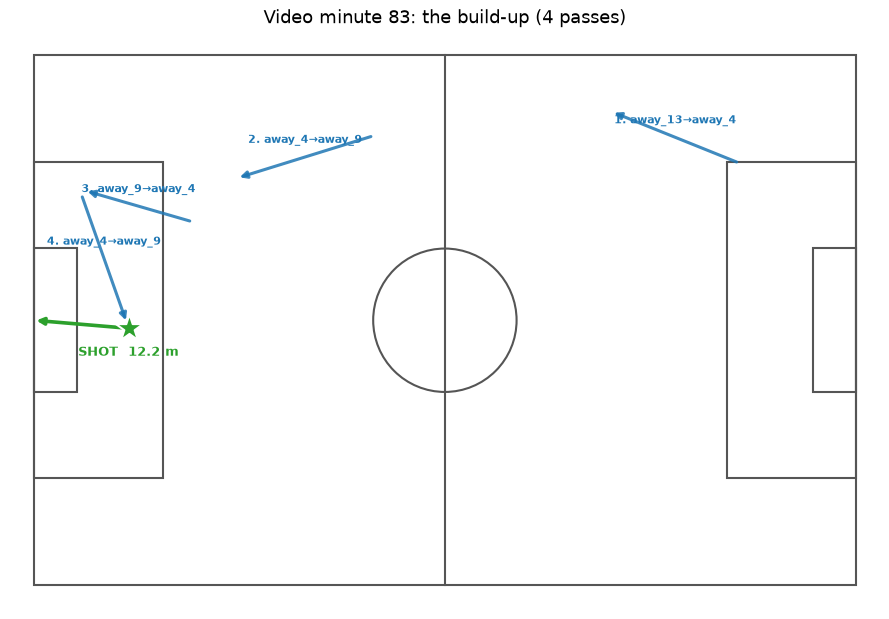

In [7]:
ax = draw_pitch()

passes = move[
    (move.event_name == "pass") & move.x_start.notna() & move.receiver_x.notna()
]
for i, r in enumerate(passes.itertuples(), 1):
    ax.annotate(
        "",
        xy=(r.receiver_x, r.receiver_y),
        xytext=(r.x_start, r.y_start),
        arrowprops=dict(
            arrowstyle="-|>", lw=2.2, color="#1f77b4", alpha=0.85, shrinkA=6, shrinkB=6
        ),
        zorder=3,
    )
    mx, mz = (r.x_start + r.receiver_x) / 2, (r.y_start + r.receiver_y) / 2
    ax.text(
        mx,
        mz + 1.8,
        f"{i}. {r.player_id}→{r.receiver_player_id}",
        ha="center",
        fontsize=8,
        color="#1f77b4",
        fontweight="bold",
        zorder=4,
    )

shot = move[move.event_name == "shot"]
if len(shot):
    s = shot.iloc[-1]
    ax.scatter(
        s.x_start,
        s.y_start,
        s=420,
        marker="*",
        c="#2ca02c",
        edgecolor="white",
        lw=1.5,
        zorder=6,
    )
    ax.annotate(
        "",
        xy=(52.5 * s.attack_dir, 0),
        xytext=(s.x_start, s.y_start),
        arrowprops=dict(arrowstyle="-|>", lw=2.6, color="#2ca02c"),
        zorder=5,
    )
    ax.text(
        s.x_start,
        s.y_start - 3.5,
        f"SHOT  {s.shot_distance_m:.1f} m",
        ha="center",
        fontsize=9,
        color="#2ca02c",
        fontweight="bold",
    )

plt.title(
    f"Video minute {GOAL.minute:.0f}: the build-up ({len(passes)} passes)", fontsize=13
)
plt.show()

## Step 6: Freeze-frame at the shot

Now the thing events alone can't tell you: where were the other 21 players?


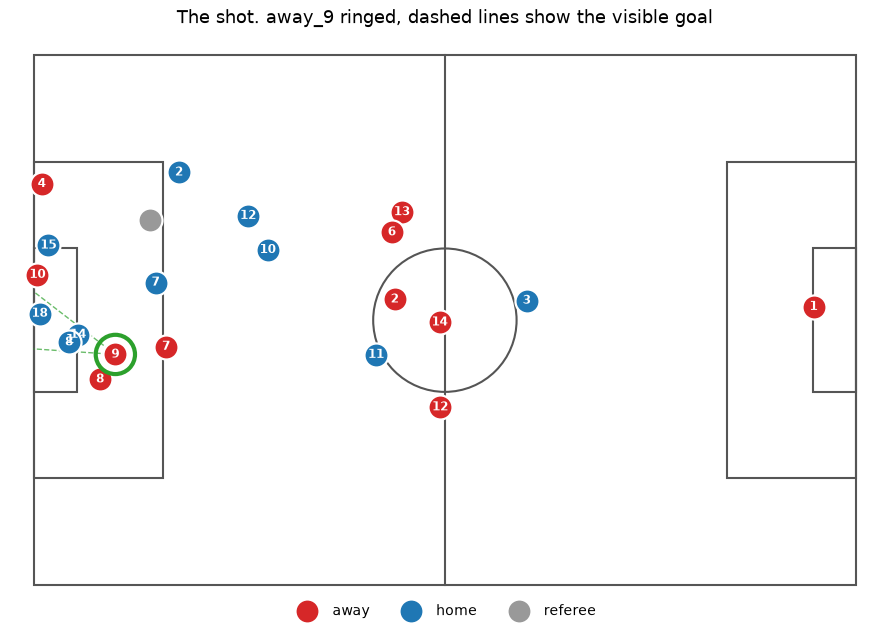

In [8]:
frame = track[track.timestamp_ms == track.timestamp_ms[track.t_rel.abs().idxmin()]]
shooter = shot.iloc[-1].player_id if len(shot) else None

ax = draw_pitch()
for team, g in frame.groupby("team"):
    ax.scatter(
        g.x,
        g.y,
        s=300,
        c=COLOURS[team],
        edgecolor="white",
        lw=1.6,
        zorder=3,
        label=team,
    )
    for r in g.itertuples():
        if pd.notna(r.player_id):
            ax.text(
                r.x,
                r.y,
                r.player_id.split("_")[1],
                ha="center",
                va="center",
                color="white",
                fontsize=8.5,
                fontweight="bold",
                zorder=4,
            )

sh = frame[frame.player_id == shooter]
if len(sh):
    ax.scatter(sh.x, sh.y, s=800, facecolor="none", edgecolor="#2ca02c", lw=3, zorder=5)
    gx = 52.5 * shot.iloc[-1].attack_dir  # the goal he is shooting at
    for post_z in (-3.66, 3.66):  # the angle the shooter actually sees
        ax.plot(
            [sh.x.iloc[0], gx],
            [sh.y.iloc[0], post_z],
            color="#2ca02c",
            lw=1,
            ls="--",
            alpha=0.7,
            zorder=2,
        )

b = frame.iloc[0]
if pd.notna(b.ball_x):
    ax.scatter(
        b.ball_x,
        b.ball_y,
        s=130,
        c="white",
        edgecolor="black",
        lw=2,
        zorder=6,
        label="ball",
    )

ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.03), ncol=4, frameon=False)
plt.title(
    f"The shot. {shooter} ringed, dashed lines show the visible goal", fontsize=13
)
plt.show()

## Step 7: The whole move as a time-lapse

Four frames across the build-up. Faint trails show where each player came from.


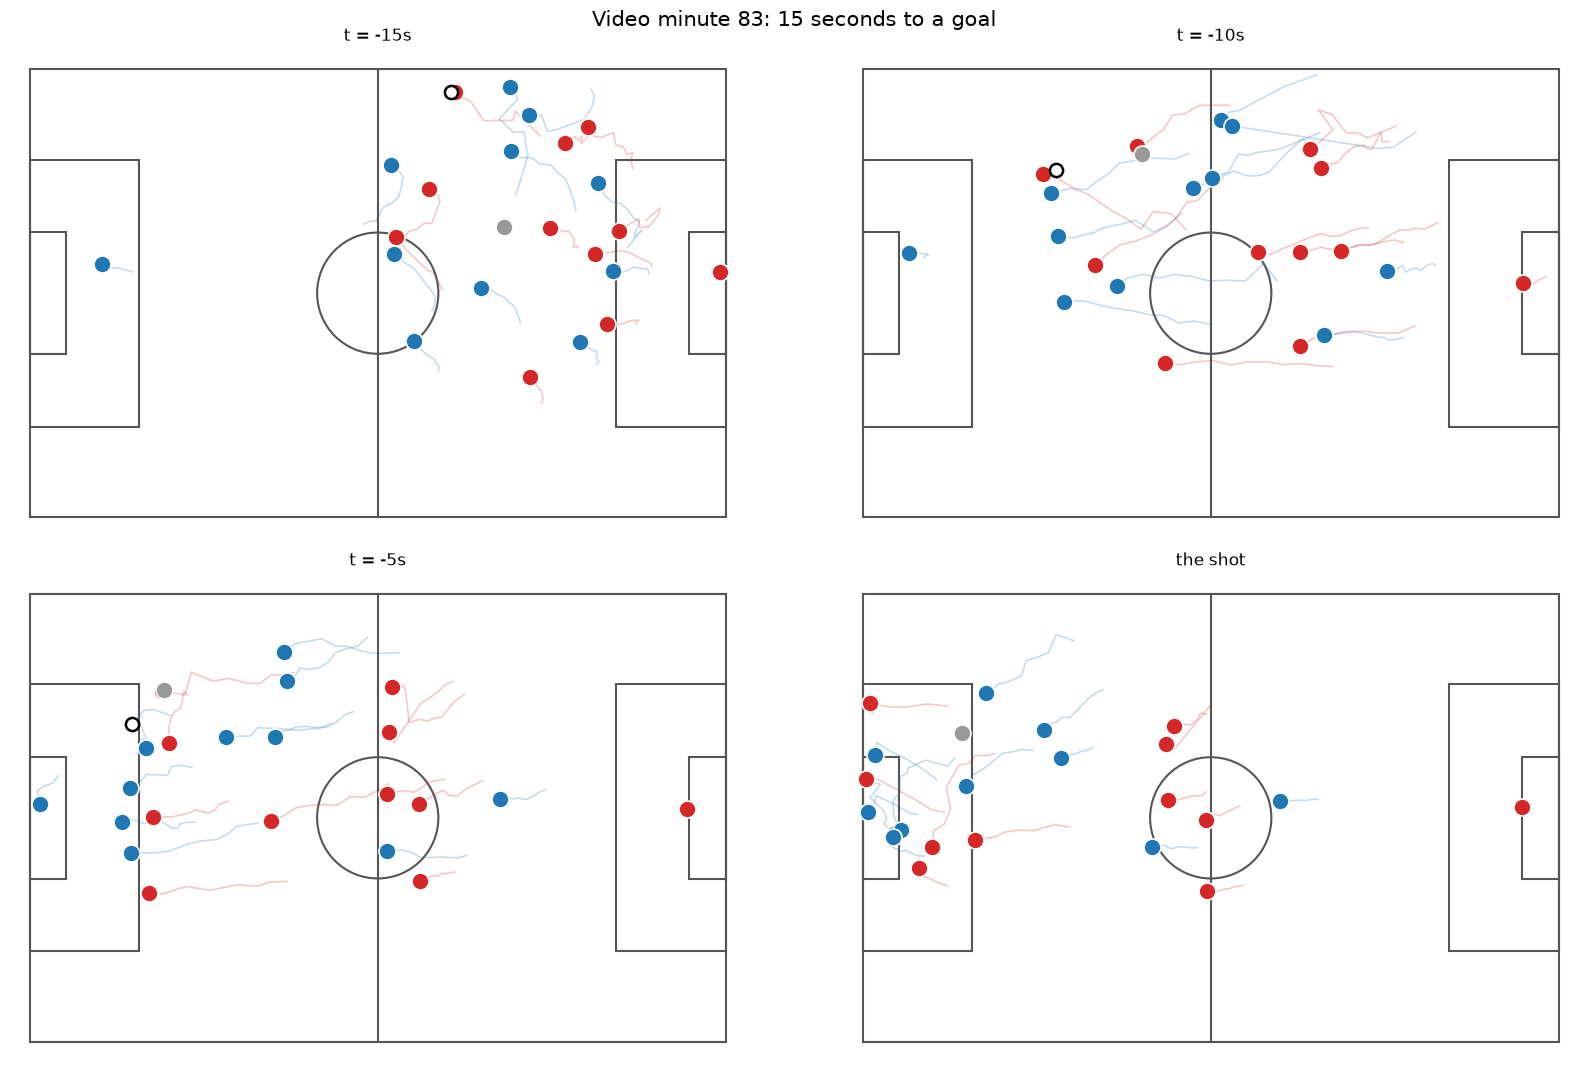

In [9]:
marks = [-15, -10, -5, 0]
fig, axes = plt.subplots(2, 2, figsize=(17, 11))

for ax, m in zip(axes.ravel(), marks):
    draw_pitch(ax)
    snap_t = track.timestamp_ms[(track.t_rel - m).abs().idxmin()]
    snap = track[track.timestamp_ms == snap_t]

    trail = track[(track.t_rel <= snap.t_rel.iloc[0]) & (track.t_rel >= m - 4)]
    for pid, g in trail[trail.player_id.notna()].groupby("player_id"):
        g = g.sort_values("timestamp_ms")
        ax.plot(g.x, g.y, color=COLOURS[g.team.iloc[0]], alpha=0.25, lw=1.2, zorder=2)

    for team, g in snap.groupby("team"):
        ax.scatter(
            g.x, g.y, s=150, c=COLOURS[team], edgecolor="white", lw=1.2, zorder=3
        )

    bb = snap.iloc[0]
    if pd.notna(bb.ball_x):
        ax.scatter(
            bb.ball_x, bb.ball_y, s=90, c="white", edgecolor="black", lw=1.8, zorder=5
        )
    ax.set_title(f"t = {m:+d}s" if m else "the shot", fontsize=12)

plt.suptitle(
    f"Video minute {GOAL.minute:.0f}: 15 seconds to a goal", fontsize=15, y=0.97
)
plt.tight_layout()
plt.show()

## Step 8: Go and watch it

The video runs on the same clock as the data, so any `timestamp_ms` converts straight
to a position in the recording. Check whether the data told you the truth.


In [10]:
secs = int(T / 1000)
print(f"Goal at {secs // 60}:{secs % 60:02d} in match_01_full.mp4   ({secs} s)")
print(f"Build-up starts at {(secs - 20) // 60}:{(secs - 20) % 60:02d}")
print()
print("The data clock and the video clock are the same:")
print("    seconds into the video = timestamp_ms / 1000")
print("so you can jump to any moment in events.csv the same way.")


Goal at 83:02 in match_01_full.mp4   (4982 s)
Build-up starts at 82:42

The data clock and the video clock are the same:
    seconds into the video = timestamp_ms / 1000
so you can jump to any moment in events.csv the same way.


## What to take from this

The pattern generalises to any moment in the match:

1. **Find a `timestamp_ms`** from `events.csv`: a goal, a turnover, a save
2. **Filter both files** to a window around it, using the same integer key, with no merge
3. **Events give you the story**, tracking gives you everything off the ball
4. **Check it against the video**

Try it on something else:

- The other five goals: is there a pattern to how they're created?
- A turnover: use `sequence_id` to find where possession changed, then watch what
  the defensive shape did in the next 10 seconds
- A save: what did the goalkeeper's positioning look like in the seconds before?
